# Getting the environment set up.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.cluster as cluster
import time
%matplotlib inline
sns.set_context('poster')
sns.set_color_codes()
plot_kwds = {'alpha' : 0.5, 's' : 20, 'linewidths':3}

In [ ]:
data = np.load('/content/data.npy')
# First 5 Rows
print(data[:5])

[[ 0.84219027  0.03995678]
 [ 0.57487825 -0.43018898]
 [-0.33429872  0.85586816]
 [ 0.75188718  0.56642066]
 [ 1.9682912   0.45406949]]


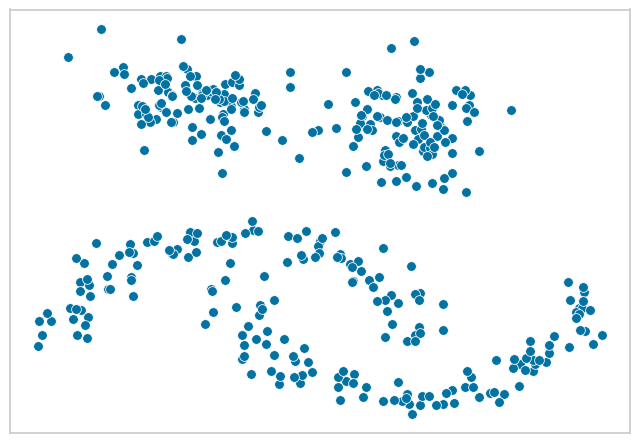

In [ ]:
# Scatterplot
ax = sns.scatterplot(x=data.T[0], y=data.T[1])

# Hide the axes
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)


# Clustering & Plotting

In [ ]:
# Function to Cluster and plot
def plot_clusters(data, algorithm, args, kwds):
  start_time = time.time()
  labels = algorithm(*args, **kwds).fit_predict(data)
  end_time = time.time()
  palette = sns.color_palette('deep', np.unique(labels).max() + 1)
  colors = [palette[x] if x >= 0 else (0.0, 0.0, 0.0) for x in labels]
  plt.scatter(data.T[0], data.T[1], c=colors, **plot_kwds)
  frame = plt.gca()
  frame.axes.get_xaxis().set_visible(False)
  frame.axes.get_yaxis().set_visible(False)
  plt.title('Clusters found by {}'.format(str(algorithm.__name__)), fontsize=24)
  plt.text(-0.5, 0.7, 'Clustering took {:.2f} s'.format(end_time - start_time),
  fontsize=14)

In [ ]:
# installation of Yellowbrick & HDBSCAN
!pip install hdbscan
!pip install yellowbrick

  Using cached hdbscan-0.8.33.tar.gz (5.2 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached Cython-0.29.37-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.manylinux_2_24_x86_64.whl (1.9 MB)
  Created wheel for hdbscan: filename=hdbscan-0.8.33-cp310-cp310-linux_x86_64.whl size=3039295 sha256=3d87673840cb4fa82a69f85af25f2a5f489e86aa777caeeb6d8374d769d1f66a
  Stored in directory: /root/.cache/pip/wheels/75/0b/3b/dc4f60b7cc455efaefb62883a7483e76f09d06ca81cf87d610
Successfully built hdbscan
  Attempting uninstall: cython
    Found existing installation: Cython 3.0.6
    Uninstalling Cython-3.0.6:
      Successfully uninstalled Cython-3.0.6


In [ ]:
# Import Algorithms
from sklearn.cluster import KMeans, DBSCAN, Birch, OPTICS, AffinityPropagation, AgglomerativeClustering, SpectralClustering
import hdbscan

# Find the Best K for K-Means

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:8

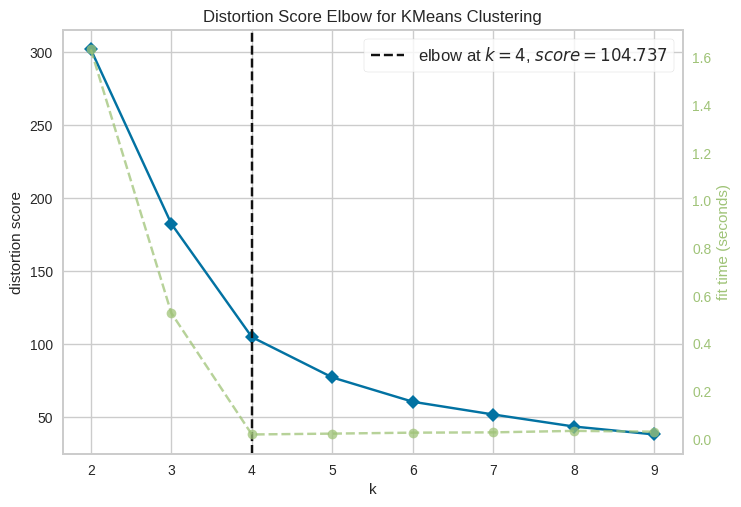

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
from yellowbrick.cluster import KElbowVisualizer
visualizer = KElbowVisualizer(KMeans(init='k-means++'), k=(2,10))
visualizer.fit(data)
visualizer.show()

# Cluster Test of Each Algorithms

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


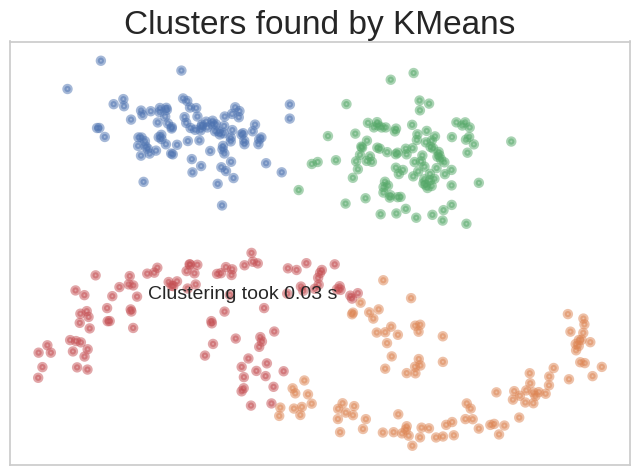

In [ ]:
# Test and plot K-Means
plot_clusters(data, KMeans, (), {'n_clusters': 4, 'init':'k-means++'})

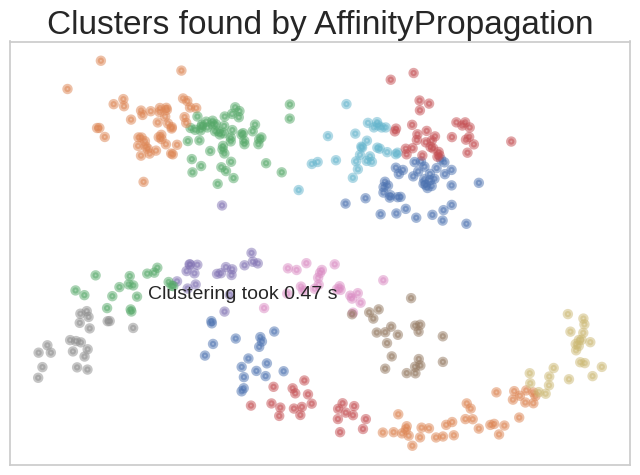

In [ ]:
# Test and plot Affinity Propagation
plot_clusters(data, AffinityPropagation, (), {'convergence_iter': 12})

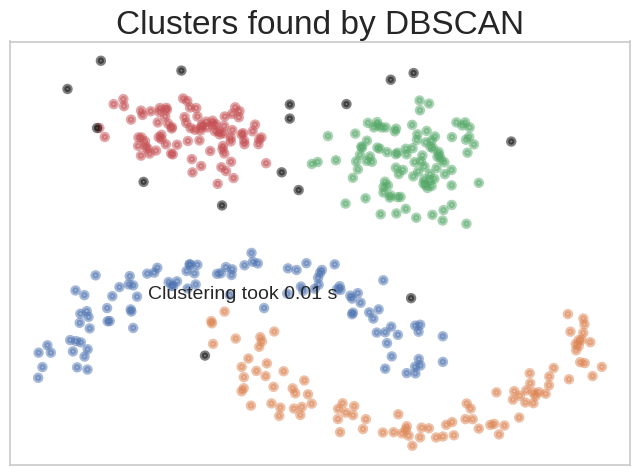

In [ ]:
# Test and plot DBSCAN with adjusted parameters
plot_clusters(data, DBSCAN, (), {'eps': 0.2, 'min_samples': 5})


**Best** K For Birch

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_birch.py:726: ConvergenceWarning: Number of subclusters found (8) by BIRCH is less than (9). Decrease the threshold.
  warnings.warn(


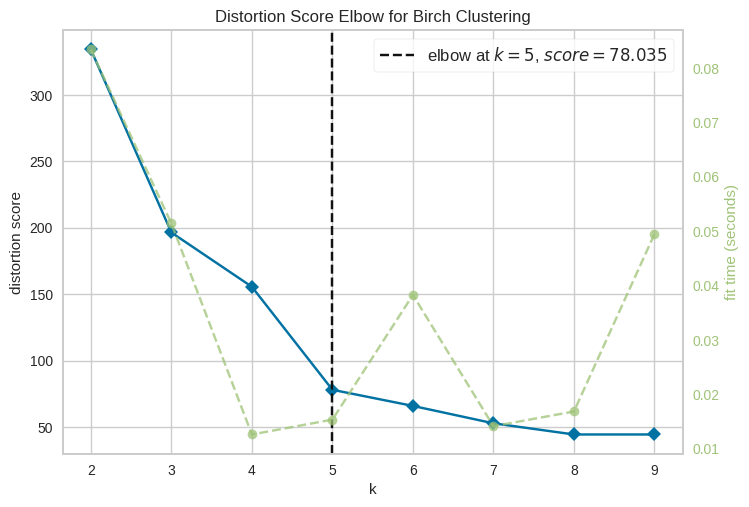

<Axes: title={'center': 'Distortion Score Elbow for Birch Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
visualizer = KElbowVisualizer(Birch(), k=(2,10))
visualizer.fit(data)
visualizer.show()

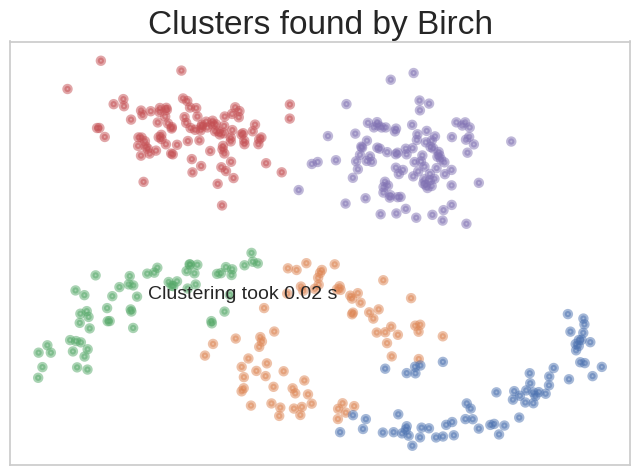

In [ ]:
# Test and plot Birch
plot_clusters(data, Birch, (), {'n_clusters': 5})


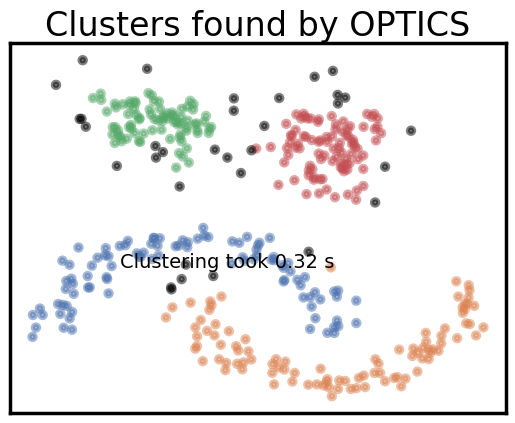

In [ ]:
# Test and plot OPTICS
plot_clusters(data, OPTICS, (), {'min_samples': 3, 'xi': 0.04, 'min_cluster_size': 0.2})

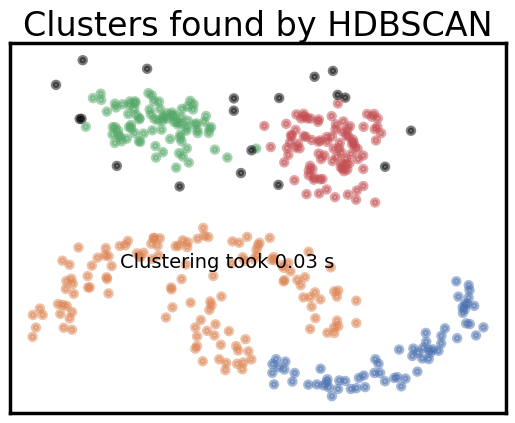

In [ ]:
# Test and plot HDBSCAN
plot_clusters(data, hdbscan.HDBSCAN, (), {'min_cluster_size': 4})

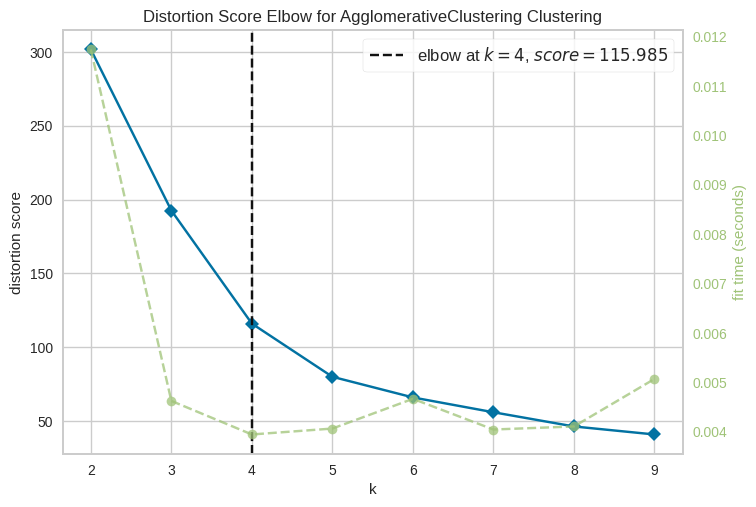

<Axes: title={'center': 'Distortion Score Elbow for AgglomerativeClustering Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
# Best K for Agglomerative
visualizer = KElbowVisualizer(AgglomerativeClustering(), k=(2,10))
visualizer.fit(data)
visualizer.show()

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_agglomerative.py:983: FutureWarning: Attribute `affinity` was deprecated in version 1.2 and will be removed in 1.4. Use `metric` instead
  warnings.warn(


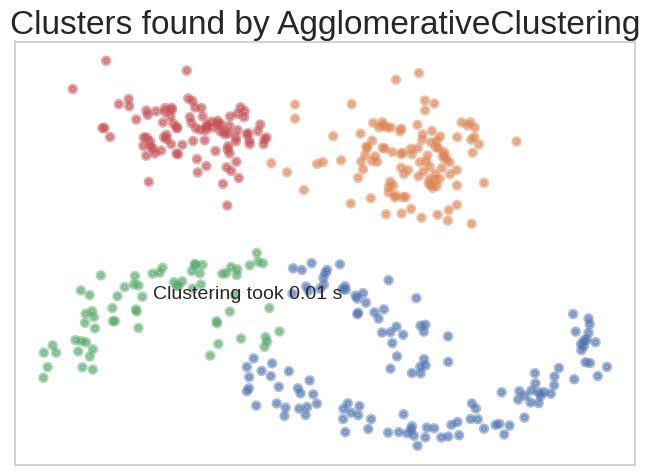

In [ ]:
# Test and plot Agglomerative Clustering
plot_clusters(data, AgglomerativeClustering, (), {'n_clusters': 4, 'affinity':'euclidean', 'linkage': 'ward'})

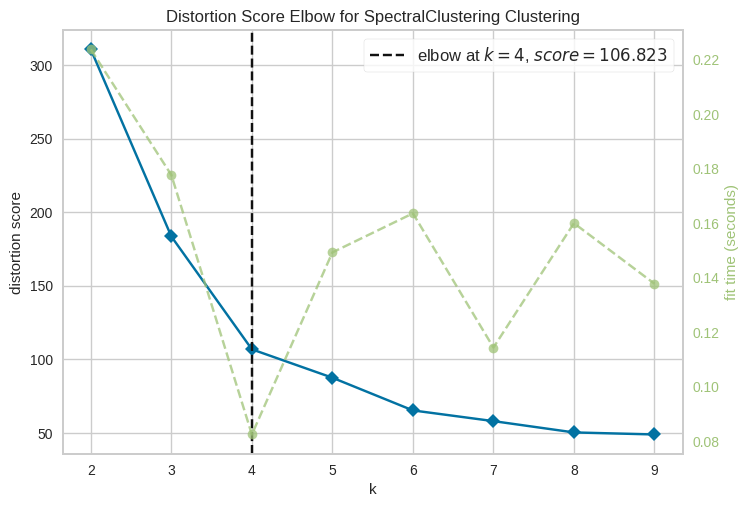

<Axes: title={'center': 'Distortion Score Elbow for SpectralClustering Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
# Best K for Spectral
visualizer = KElbowVisualizer(SpectralClustering(), k=(2,10))
visualizer.fit(data)
visualizer.show()

/usr/local/lib/python3.10/dist-packages/sklearn/manifold/_spectral_embedding.py:274: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


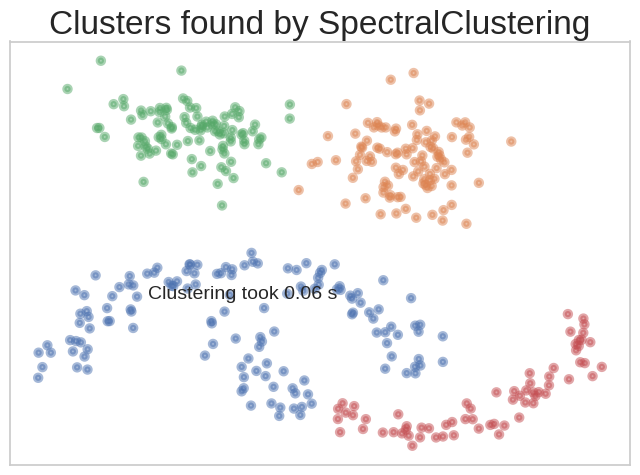

In [ ]:
# Test and plot Spectral Clustering
plot_clusters(data, SpectralClustering, (), {'n_clusters': 4, 'affinity': 'nearest_neighbors'})